In [1]:
import matplotlib.pyplot as plt
import pandas as pd

oil = pd.read_csv("../data/clean/weekly_DCOILWTICO.csv", parse_dates=["observation_date", "available_at"])
fx = pd.read_csv("../data/clean/weekly_DEXINUS.csv", parse_dates=["observation_date", "available_at"])

for name, t in [("oil", oil), ("rupee", fx)]:
    print(name, len(t), "weeks;", int(t.is_missing.sum()), "missing;", int(t.is_filled.sum()), "filled;", int(t.is_outlier.sum()), "outliers")

oil 2128 weeks; 0 missing; 3 filled; 83 outliers
rupee 2806 weeks; 0 missing; 0 filled; 296 outliers


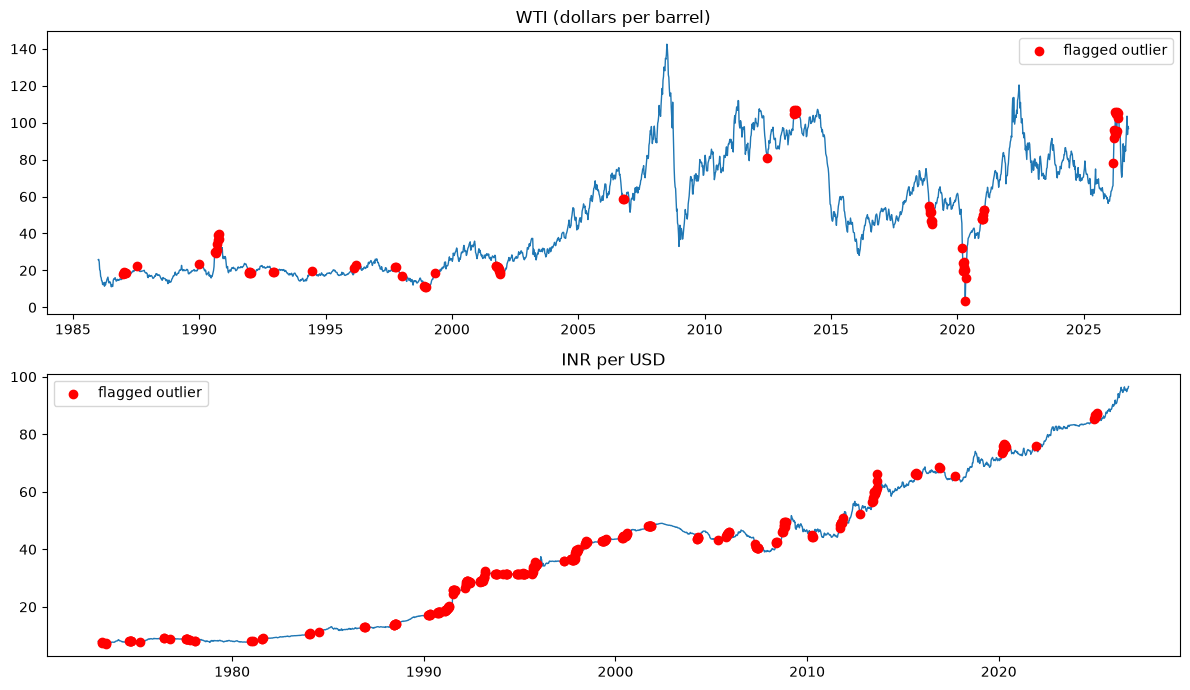

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
for ax, (name, t) in zip(axes, [("WTI (dollars per barrel)", oil), ("INR per USD", fx)]):
    ax.plot(t["observation_date"], t["value"], lw=1)
    out = t[t["is_outlier"]]
    ax.scatter(out["observation_date"], out["value"], color="red", zorder=3, label="flagged outlier")
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()

In [3]:
print(oil[oil["is_outlier"]][["observation_date", "value", "robust_z"]].tail(10))
print((oil["available_at"] - oil["observation_date"]).dt.days.value_counts())
print(oil["n_daily_obs"].value_counts())

     observation_date    value   robust_z
2097       2026-03-13   91.850   9.156563
2098       2026-03-20   96.068  10.391373
2099       2026-03-27   94.292   9.871453
2100       2026-04-03  105.670  13.202337
2101       2026-04-10  104.544  12.230395
2102       2026-04-17   93.840   8.838585
2103       2026-04-24   95.430   7.629414
2104       2026-05-01  105.566   7.726001
2105       2026-05-08  102.284   5.471833
2106       2026-05-15  105.102   4.898545
5    2128
Name: count, dtype: int64
n_daily_obs
5    1383
4     488
3     162
2      75
1      17
0       3
Name: count, dtype: int64
